# Práctica: Evaluación de algoritmos de clustering
**Curso:** Minería de Datos / Aprendizaje no supervisado · EPIS – UNA Puno

**Equipo:** 
Turpo Quispe Patty Milagros,  Huanca Chahuara Cyntia Mariela,  Carrazco Yupanqui Edilza Luz,  Quispe Hualla Yuri Florentino


**Repositorio GitHub:** https://github.com/PattyTurpo/Clustering.git

---

## Objetivo
Entrenar y comparar **K-means**, **DBSCAN** y **SpectralClustering** sobre tres datasets (**Iris**, **Moons** y **Circles**), evaluándolos con métricas de validación **externas** (necesitan las etiquetas reales) e **internas** (solo usan los datos y los clústeres encontrados), y explicar por qué cada modelo se comporta como lo hace.

## Métricas usadas

| Tipo | Métrica | Qué mide | Mejor valor |
|---|---|---|---|
| Externa | **ARI** (Adjusted Rand Index) | Concordancia entre clústeres y clases reales, corregida por azar. Puede ser negativa. | Cercano a **1** (≈0 = azar) |
| Externa | **V-measure** | Media armónica de *homogeneidad* (cada clúster tiene una sola clase) y *completitud* (cada clase cae en un solo clúster). | Cercano a **1** |
| Interna | **Silhouette** | Cohesión vs. separación: compara la distancia media intra-clúster (a) con la del clúster vecino más cercano (b). Rango [-1, 1]. | Cercano a **1** |
| Interna | **Davies-Bouldin (DBI)** | Promedio de la similitud entre cada clúster y su vecino más parecido (dispersión interna / distancia entre centroides). | Cercano a **0** (menor es mejor) |
| Interna | **Elbow (codo)** | Inercia (WSS) de K-means al variar *k*; se busca el punto donde la mejora se aplana. | Punto de inflexión |

> Se agrega también *Calinski-Harabasz* como métrica interna complementaria (aparece en el material del curso).


In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.metrics import (adjusted_rand_score, v_measure_score,
                             homogeneity_score, completeness_score,
                             silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)

warnings.filterwarnings("ignore")
SEED = 42
os.makedirs("figuras", exist_ok=True)      # aquí se guardan los gráficos para el informe / GitHub
os.makedirs("resultados", exist_ok=True)   # aquí se guardan las tablas CSV
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
print("Listo ✔")

Listo ✔


## 0. Funciones auxiliares
Una sola función `evaluar()` calcula todas las métricas, para que la comparación sea justa entre modelos y datasets.

**Nota sobre DBSCAN:** marca con `-1` los puntos que considera *ruido*. Para las métricas **externas** el ruido se trata como un clúster más (así penaliza si el modelo descarta muchos puntos). Para las métricas **internas** se calculan **sin** los puntos de ruido, y solo si existen al menos 2 clústeres.

In [2]:
def evaluar(X, y, labels):
    """Devuelve un diccionario con métricas externas e internas."""
    labels = np.asarray(labels)
    mask = labels != -1                                   # puntos que NO son ruido
    n_clusters = len(set(labels[mask]))
    out = {
        "n_clusters": n_clusters,
        "% ruido": round(100 * (~mask).mean(), 1),
        # --- Validación EXTERNA (usa las etiquetas reales y) ---
        "ARI": adjusted_rand_score(y, labels),
        "V-measure": v_measure_score(y, labels),
        "Homogeneidad": homogeneity_score(y, labels),
        "Completitud": completeness_score(y, labels),
    }
    # --- Validación INTERNA (solo X y los clústeres) ---
    if n_clusters >= 2:
        out["Silhouette"] = silhouette_score(X[mask], labels[mask])
        out["Davies-Bouldin"] = davies_bouldin_score(X[mask], labels[mask])
        out["Calinski-Harabasz"] = calinski_harabasz_score(X[mask], labels[mask])
    else:
        out["Silhouette"] = out["Davies-Bouldin"] = out["Calinski-Harabasz"] = np.nan
    return out


def comparar(X, y, modelos):
    """Entrena cada modelo, evalúa y devuelve (tabla de métricas, dict de etiquetas)."""
    filas, etiquetas = {}, {}
    for nombre, modelo in modelos.items():
        lab = modelo.fit_predict(X)
        etiquetas[nombre] = lab
        filas[nombre] = evaluar(X, y, lab)
    return pd.DataFrame(filas).T.round(3), etiquetas


def graficar(X2d, y, etiquetas, titulo, archivo, xlabel="x1", ylabel="x2"):
    """Dibuja: etiquetas reales + resultado de cada modelo. El ruido de DBSCAN sale como 'x' negra."""
    paneles = {"Etiquetas reales": y, **etiquetas}
    fig, axs = plt.subplots(1, len(paneles), figsize=(4.2 * len(paneles), 4))
    for ax, (nombre, lab) in zip(axs, paneles.items()):
        lab = np.asarray(lab); ruido = lab == -1
        ax.scatter(X2d[~ruido, 0], X2d[~ruido, 1], c=lab[~ruido], cmap="viridis", s=18, edgecolor="none")
        if ruido.any():
            ax.scatter(X2d[ruido, 0], X2d[ruido, 1], c="k", marker="x", s=22, label=f"ruido ({ruido.sum()})")
            ax.legend(loc="best", fontsize=8)
        ax.set_title(nombre, fontsize=11); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    fig.suptitle(titulo, fontsize=13, y=1.02)
    fig.tight_layout(); fig.savefig(f"figuras/{archivo}.png", bbox_inches="tight"); plt.show()


def elbow(X, nombre, kmax=10):
    """Método del codo (inercia) + Silhouette promedio para k = 2..kmax con K-means."""
    ks = range(1, kmax + 1)
    inercia = [KMeans(k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks]
    sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=SEED).fit_predict(X)) for k in range(2, kmax + 1)]
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
    axs[0].plot(ks, inercia, "o-"); axs[0].set_title(f"Elbow – {nombre}"); axs[0].set_xlabel("k"); axs[0].set_ylabel("Inercia (WSS)")
    axs[1].plot(range(2, kmax + 1), sil, "o-", color="tab:orange"); axs[1].set_title(f"Silhouette vs k – {nombre}"); axs[1].set_xlabel("k"); axs[1].set_ylabel("Silhouette")
    fig.tight_layout(); fig.savefig(f"figuras/elbow_{nombre.lower()}.png", bbox_inches="tight"); plt.show()
    return pd.DataFrame({"k": list(ks), "inercia": np.round(inercia, 2)}).set_index("k").T


def kdist(X, k, nombre):
    """Gráfico de k-distancias: ayuda a elegir eps de DBSCAN (buscar el 'codo' de la curva)."""
    d = np.sort(NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)[0][:, -1])
    plt.figure(figsize=(5, 3.4)); plt.plot(d)
    plt.title(f"k-distancias (k={k}) – {nombre}"); plt.xlabel("puntos ordenados"); plt.ylabel(f"distancia al vecino {k}")
    plt.savefig(f"figuras/kdist_{nombre.lower()}.png", bbox_inches="tight"); plt.show()
    return np.percentile(d, [90, 95, 98]).round(3)

print("Funciones definidas ✔")

Funciones definidas ✔


## 1. Dataset Iris
150 flores, 4 características (largo/ancho de sépalo y pétalo), 3 especies reales (*setosa*, *versicolor*, *virginica*).

Siguiendo el material del curso, **estandarizamos** las variables (`StandardScaler`) porque K-means, DBSCAN y Spectral usan distancias, y una variable con mayor varianza dominaría las demás. Para graficar en 2D se usa **PCA** (solo para visualizar; los modelos se entrenan con las 4 variables).

In [3]:
iris = load_iris()
X_iris_raw, y_iris = iris.data, iris.target
X_iris = StandardScaler().fit_transform(X_iris_raw)
X_iris_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_iris)

print("Forma:", X_iris.shape, "| Clases reales:", dict(zip(iris.target_names, np.bincount(y_iris))))
print("Varianza explicada por 2 componentes PCA:", PCA(2).fit(X_iris).explained_variance_ratio_.sum().round(3))

Forma: (150, 4) | Clases reales: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}
Varianza explicada por 2 componentes PCA: 0.958


### 1.1 Elección del número de clústeres y de `eps`

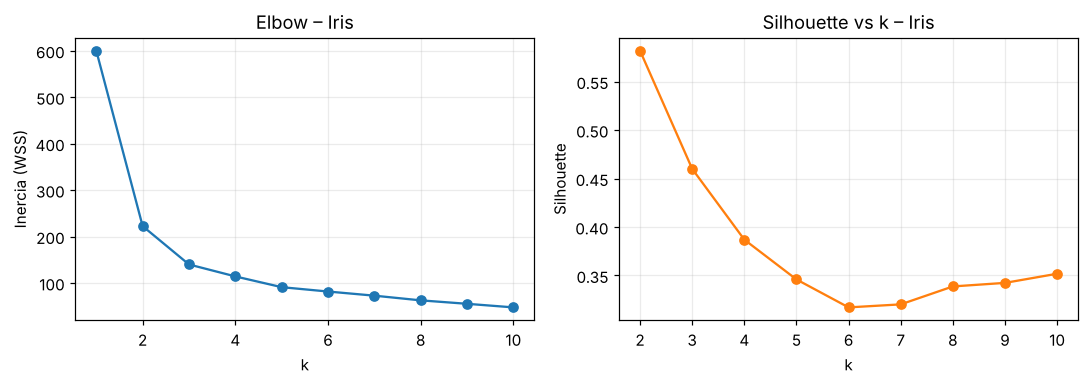

k,1,2,3,4,5,6,7,8,9,10
inercia,600.0,222.36,139.82,114.09,90.93,81.54,72.63,62.54,55.12,47.39


In [4]:
tabla_elbow_iris = elbow(X_iris, "Iris")
tabla_elbow_iris

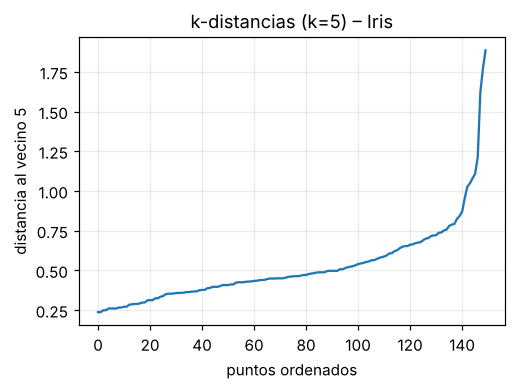

Percentiles 90/95/98 de la distancia al 5º vecino: [0.759 0.994 1.221]


,n_clusters,% ruido,ARI,Silhouette
eps,,,,
0.3,3,80.0,0.088,0.630
0.4,6,44.0,0.366,0.486
0.5,2,22.7,0.442,0.656
0.6,2,17.3,0.471,0.642
0.7,2,4.0,0.540,0.602
0.8,2,2.7,0.552,0.598
1.0,2,2.0,0.554,0.595


In [5]:
# DBSCAN: eps se elige con el gráfico de k-distancias (k = min_samples = 5)
print("Percentiles 90/95/98 de la distancia al 5º vecino:", kdist(X_iris, 5, "Iris"))

# Sensibilidad a eps (min_samples=5 fijo)
filas = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    r = evaluar(X_iris, y_iris, DBSCAN(eps=eps, min_samples=5).fit_predict(X_iris))
    filas.append({"eps": eps, "n_clusters": r["n_clusters"], "% ruido": r["% ruido"], "ARI": r["ARI"], "Silhouette": r["Silhouette"]})
pd.DataFrame(filas).set_index("eps").round(3)

### 1.2 Entrenamiento y evaluación

In [6]:
modelos_iris = {
    "K-means":  KMeans(n_clusters=3, n_init=10, random_state=SEED),
    "DBSCAN":   DBSCAN(eps=0.6, min_samples=5),
    "Spectral": SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=10, random_state=SEED),
}
tabla_iris, lab_iris = comparar(X_iris, y_iris, modelos_iris)
tabla_iris.to_csv("resultados/metricas_iris.csv")
tabla_iris

,n_clusters,% ruido,ARI,V-measure,Homogeneidad,Completitud,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-means,3.0,0.0,0.620,0.659,0.659,0.660,0.460,0.834,241.904
DBSCAN,2.0,17.3,0.471,0.541,0.518,0.566,0.642,0.512,330.917
Spectral,3.0,0.0,0.646,0.684,0.674,0.694,0.459,0.822,229.680


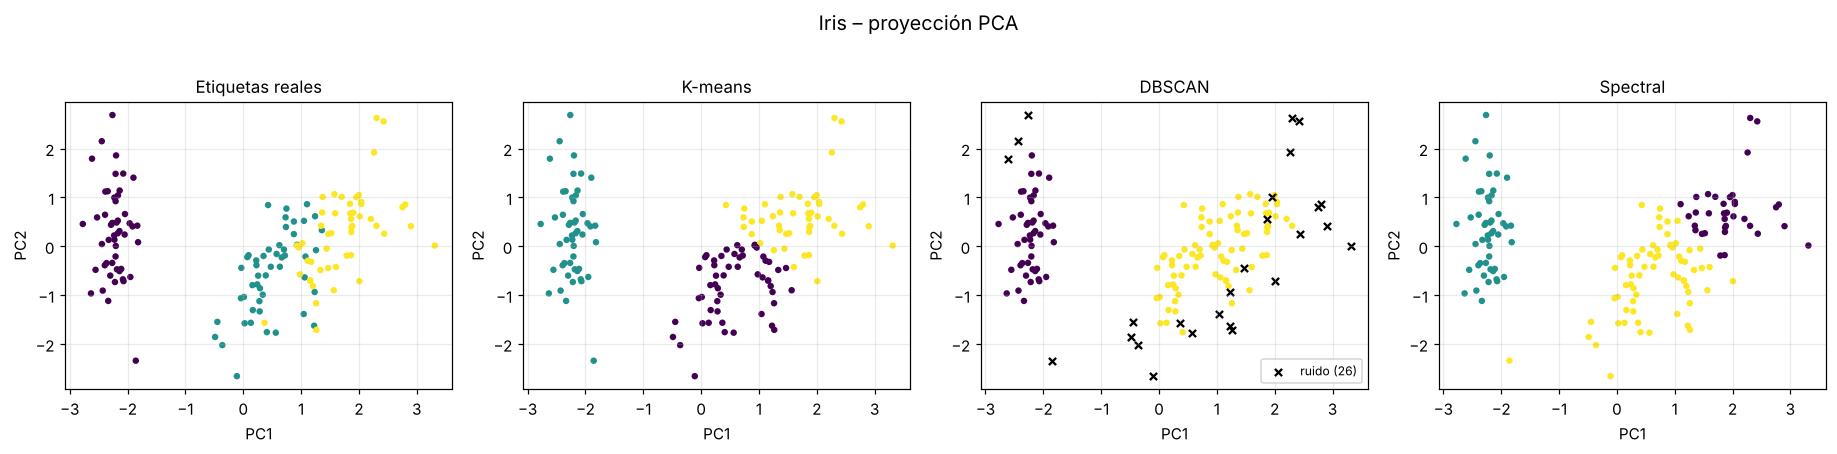


=== K-means ===
especie  setosa  versicolor  virginica
clúster                               
0             0          39         14
1            50           0          0
2             0          11         36

=== DBSCAN ===
especie  setosa  versicolor  virginica
clúster                               
-1            4           8         14
 0           46           0          0
 1            0          42         36

=== Spectral ===
especie  setosa  versicolor  virginica
clúster                               
0             0           3         32
1            49           0          0
2             1          47         18


In [7]:
graficar(X_iris_2d, y_iris, lab_iris, "Iris – proyección PCA", "iris_modelos", "PC1", "PC2")

# Tabulación cruzada clúster vs especie (como en el material del curso)
for nombre, lab in lab_iris.items():
    print(f"\n=== {nombre} ===")
    print(pd.crosstab(pd.Series(lab, name="clúster"), pd.Series(iris.target_names[y_iris], name="especie")))

**Extra (conecta con el material de clase):** ¿realmente ayudó estandarizar en Iris? En el dataset *wine* del curso sí mejoraba muchísimo porque las variables tenían escalas muy distintas (proline ≈ 99 166 de varianza). En Iris todas las medidas están en centímetros.

In [8]:
ari_raw = adjusted_rand_score(y_iris, KMeans(3, n_init=10, random_state=SEED).fit_predict(X_iris_raw))
ari_std = adjusted_rand_score(y_iris, KMeans(3, n_init=10, random_state=SEED).fit_predict(X_iris))
print(f"K-means en Iris  sin estandarizar: ARI = {ari_raw:.3f}   |   estandarizado: ARI = {ari_std:.3f}")
print("Varianzas por variable (sin estandarizar):", X_iris_raw.var(axis=0).round(2))

K-means en Iris  sin estandarizar: ARI = 0.730   |   estandarizado: ARI = 0.620
Varianzas por variable (sin estandarizar): [0.68 0.19 3.1  0.58]


### 1.3 Explicación del comportamiento de los modelos con Iris

*(Cifras obtenidas con `random_state=42`; pueden variar levemente según la versión de scikit-learn.)*

**Estructura real de Iris:** *setosa* está claramente separada, pero *versicolor* y *virginica* **se solapan** en el espacio de las 4 variables. Esto condiciona a los tres modelos.

**K-means (k=3).** Separa *setosa* de forma perfecta (50/50) y reparte el resto en dos grupos compactos. Los errores están en la zona de solapamiento: el clúster 0 contiene 39 versicolor + 14 virginica y el clúster 2 contiene 11 versicolor + 36 virginica. Funciona razonablemente porque Iris tiene grupos más o menos esféricos y le dimos el *k* correcto. El método del codo no es tajante: la mayor caída está entre k=1 y k=2 (600 → 222) y hay una segunda inflexión en k=3 (≈140); k=3 se elige por conocimiento del dominio (3 especies) y porque el codo ya se aplana desde ahí. Ojo: el gráfico de Silhouette vs k favorece k=2 (0.58 frente a 0.46 con k=3), porque versicolor y virginica se solapan y se perciben como un solo bloque; es la misma razón por la que DBSCAN encuentra 2 clústeres. Por eso conviene justificar k=3 con el conocimiento del dominio y no solo con las métricas.

**DBSCAN (eps=0.6, min_samples=5).** Encuentra solo **2 clústeres**: *setosa* (46 puntos) y un bloque grande que **fusiona versicolor y virginica** (42 + 36), y marca **26 puntos (17.3 %) como ruido**. DBSCAN no ve "tres especies" porque agrupa por densidad: entre versicolor y virginica no hay un valle de baja densidad, así que forman una sola región conectada. Es muy sensible a `eps`: con eps=0.3 el 80 % de los puntos son ruido; con eps≥0.7 el ruido baja a ≤4 % pero sigue habiendo solo 2 clústeres (la tabla de la sección 1.1 lo muestra).

**SpectralClustering (3 clústeres, vecinos más cercanos).** Resultado muy parecido a K-means, ligeramente mejor (setosa 49/50; versicolor 47 bien asignadas). Como Iris no tiene formas complejas, el grafo de afinidad no aporta una ventaja real sobre K-means.

**¿Ayudó estandarizar?** No en este caso: K-means sin estandarizar da ARI ≈ 0.73 y estandarizado ≈ 0.62. En *wine* la estandarización era crucial (una variable tenía varianza ≈ 99 166), pero en Iris todas las medidas están en cm y sus varianzas son comparables (0.19–3.1); al estandarizar, la variable menos informativa (ancho de sépalo) gana el mismo peso que las muy informativas (pétalo). Estandarizar es una buena práctica por defecto, pero conviene verificar su efecto.

### 1.4 Significado de las métricas en Iris

| Modelo | ARI | V-measure | Silhouette | Davies-Bouldin |
|---|---|---|---|---|
| K-means | 0.620 | 0.659 | 0.460 | 0.834 |
| DBSCAN | 0.471 | 0.541 | 0.642 | 0.512 |
| Spectral | 0.646 | 0.684 | 0.459 | 0.822 |

**Externas (comparan con las especies reales).**
- **ARI ≈ 0.62–0.65 (K-means, Spectral):** concordancia buena pero no perfecta; ≈ 0 sería azar y 1 una coincidencia exacta. El error viene de mezclar versicolor/virginica.
- **ARI = 0.471 (DBSCAN):** es el peor, porque fusionó dos especies en un clúster y envió el 17 % de los puntos a ruido (que, al evaluar, cuenta como un clúster más).
- **V-measure 0.66–0.68 (K-means/Spectral):** homogeneidad ≈ 0.66 (cada clúster es bastante "puro") y completitud ≈ 0.66–0.69 (cada especie cae mayormente en un clúster). En DBSCAN, la homogeneidad (0.518) baja porque su clúster grande mezcla especies.

**Internas (no usan las especies).**
- **Silhouette 0.46 (K-means/Spectral):** estructura moderada, con clústeres que se tocan (versicolor/virginica). Valores de 0.25–0.5 se interpretan como estructura débil-razonable.
- **Silhouette 0.642 y Davies-Bouldin 0.512 (DBSCAN):** parecen "los mejores", pero es una **trampa**: solo se calculan con 2 clústeres y **sin los puntos de ruido** (justamente los de la frontera difícil). Separar *setosa* del resto es fácil, y eso infla las métricas internas.
- **Davies-Bouldin 0.82–0.83 (K-means/Spectral):** valor aceptable (menor es mejor), coherente con clústeres moderadamente separados.

**Lección:** una métrica interna alta no garantiza que la agrupación coincida con las clases reales. En Iris, **la mejor según las internas (DBSCAN) es la peor según las externas**. Conviene mirar varias métricas a la vez.

## 2. Dataset sintético *Moons*
500 puntos en forma de **dos medias lunas entrelazadas** (`make_moons`, `noise=0.07`). Son dos clases **no convexas y no linealmente separables**: ideal para ver quién entiende la *forma* de los datos y quién solo mide distancias a un centro.

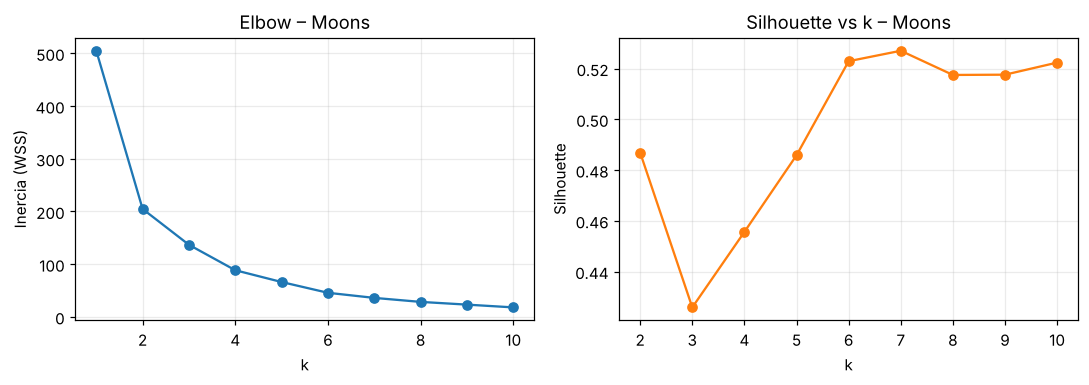

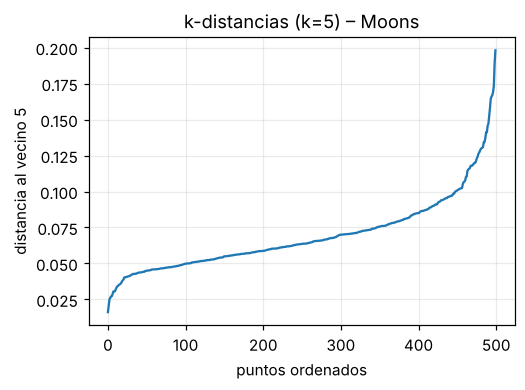

Percentiles 90/95/98 k-dist: [0.1   0.121 0.146]


k,1,2,3,4,5,6,7,8,9,10
inercia,504.93,204.75,136.78,88.55,66.18,45.73,36.07,28.48,23.29,18.05


In [9]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.07, random_state=SEED)

tabla_elbow_moons = elbow(X_moons, "Moons")
print("Percentiles 90/95/98 k-dist:", kdist(X_moons, 5, "Moons"))
tabla_elbow_moons

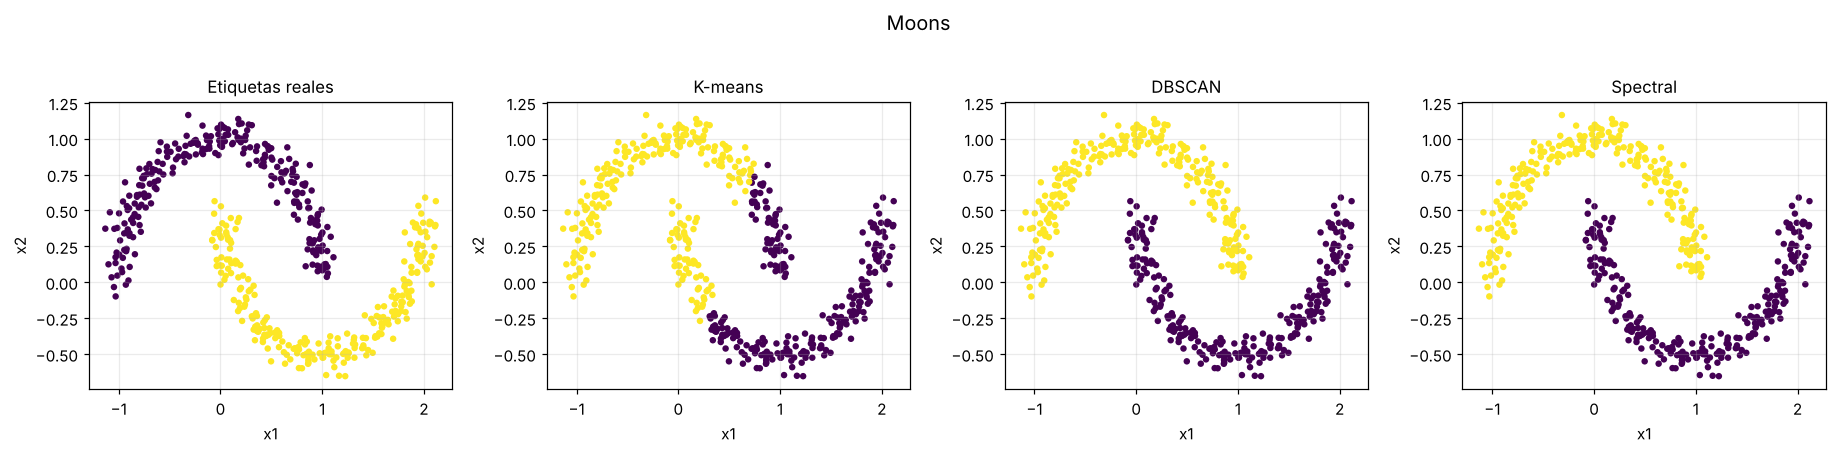

,n_clusters,% ruido,ARI,V-measure,Homogeneidad,Completitud,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-means,2.0,0.0,0.261,0.198,0.198,0.198,0.487,0.785,730.114
DBSCAN,2.0,0.0,1.000,1.000,1.000,1.000,0.332,1.153,331.338
Spectral,2.0,0.0,1.000,1.000,1.000,1.000,0.332,1.153,331.338


In [10]:
modelos_moons = {
    "K-means":  KMeans(n_clusters=2, n_init=10, random_state=SEED),
    "DBSCAN":   DBSCAN(eps=0.2, min_samples=5),
    "Spectral": SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=10, random_state=SEED),
}
tabla_moons, lab_moons = comparar(X_moons, y_moons, modelos_moons)
tabla_moons.to_csv("resultados/metricas_moons.csv")
graficar(X_moons, y_moons, lab_moons, "Moons", "moons_modelos")
tabla_moons

### 2.1 Explicación del comportamiento de los modelos con Moons

**K-means falla (ARI ≈ 0.26).** Corta el plano con una **recta** (la mediatriz entre dos centroides), así que parte cada luna por la mitad y mezcla puntos de ambas clases. Su criterio (minimizar la distancia al centroide) supone grupos compactos y convexos, y una media luna no lo es: el centroide de cada luna cae fuera de la propia figura. Tampoco el codo ayuda: la inercia baja de forma continua (505 → 205 → 137 → 89 …) sin un codo claro, porque no hay un *k* que haga "compactas" las lunas.

**DBSCAN acierta (ARI = 1.0).** Con eps=0.2 y min_samples=5 cada luna es una cadena continua de puntos vecinos densos; DBSCAN las **encadena** y, como entre ambas lunas hay un hueco, no las une. Además no etiqueta ningún punto como ruido. Es sensible a `eps`: con eps=0.1 empiezan a aparecer puntos de ruido (ARI ≈ 0.95), el rango estable está entre ≈ 0.15 y 0.3, y con eps ≥ 0.35 las dos lunas se fusionan en un único clúster (ARI = 0), como muestra el gráfico de sensibilidad de la sección 4.

**Spectral con `nearest_neighbors` acierta (ARI = 1.0).** El grafo de 10 vecinos conecta cada punto solo con su entorno local, de modo que hay dos componentes casi desconectados (las dos lunas) y el espectro del Laplaciano los separa. Con `affinity="rbf"` y `gamma=1` (valor por defecto) falla (ARI ≈ 0.28); necesita `gamma ≥ 10–20` para que la afinidad sea lo bastante local. También `n_neighbors` importa: con 3 vecinos el grafo se rompe en demasiados trozos (ARI = 0).

### 2.2 Significado de las métricas en Moons

| Modelo | ARI | V-measure | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|---|
| K-means | 0.261 | 0.198 | **0.487** | **0.785** | **730** |
| DBSCAN | **1.000** | **1.000** | 0.332 | 1.153 | 331 |
| Spectral | **1.000** | **1.000** | 0.332 | 1.153 | 331 |

**Externas:** ARI y V-measure = 1 para DBSCAN y Spectral significan que **recuperan exactamente las dos lunas** (homogeneidad y completitud = 1). En K-means, V-measure = 0.198 indica que sus clústeres casi no informan sobre la clase real.

**Internas: aquí se invierte el ranking.** K-means obtiene el *mejor* Silhouette (0.487), el menor Davies-Bouldin (0.785) y el mayor Calinski-Harabasz, pese a ser el modelo equivocado. La razón es que estas métricas miden **compacidad y separación basadas en distancias a centroides/promedios**, es decir, premian exactamente lo que K-means optimiza (clústeres redondos). Las lunas correctas son alargadas y se curvan una alrededor de la otra, por lo que tienen puntos lejanos dentro del mismo clúster y vecinos cercanos de la otra clase → Silhouette bajo (0.332).

**Conclusión:** en datos con formas no convexas, **las métricas internas clásicas no son fiables** para comparar algoritmos de familias distintas (el propio material del curso advierte que no suele ser adecuado comparar algoritmos de clúster distintos). Si se dispone de etiquetas, deben priorizarse las externas.

## 3. Dataset sintético *Circles*
500 puntos en **dos círculos concéntricos** (`make_circles`, `factor=0.4`, `noise=0.05`). Ambas clases tienen **el mismo centro**, así que ninguna frontera recta (ni ningún modelo basado en centroides) puede separarlas.

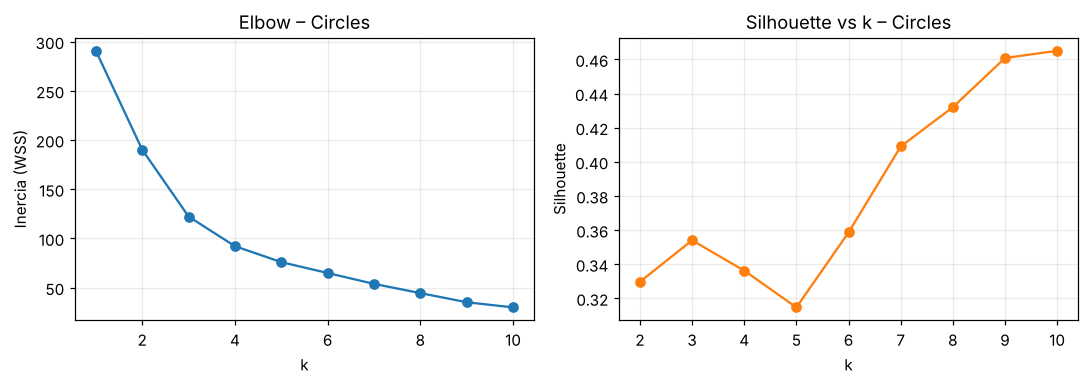

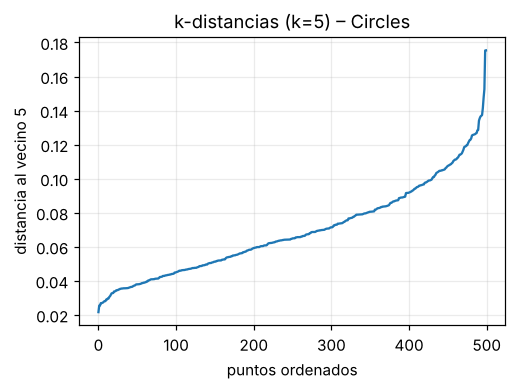

Percentiles 90/95/98 k-dist: [0.107 0.12  0.129]


k,1,2,3,4,5,6,7,8,9,10
inercia,290.68,190.11,122.22,92.08,75.89,64.81,53.76,44.38,35.1,29.86


In [11]:
X_circ, y_circ = make_circles(n_samples=500, factor=0.4, noise=0.05, random_state=SEED)

tabla_elbow_circ = elbow(X_circ, "Circles")
print("Percentiles 90/95/98 k-dist:", kdist(X_circ, 5, "Circles"))
tabla_elbow_circ

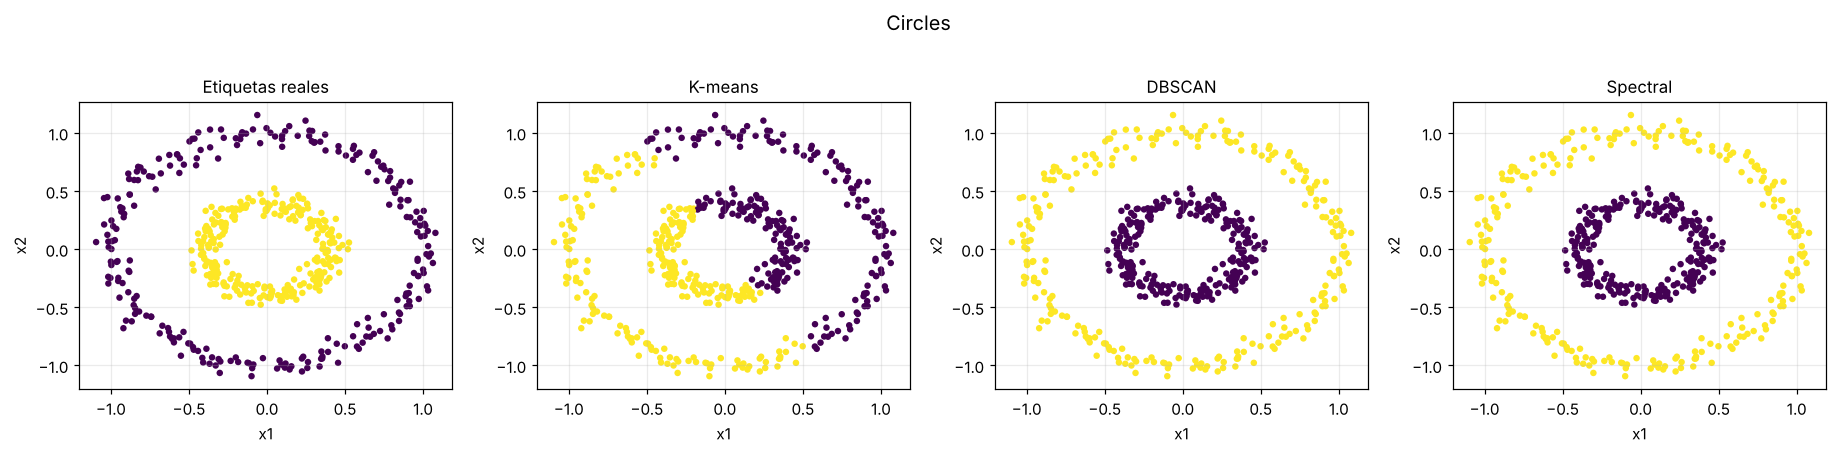

,n_clusters,% ruido,ARI,V-measure,Homogeneidad,Completitud,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-means,2.0,0.0,-0.002,0.0,0.0,0.0,0.330,1.221,263.43
DBSCAN,2.0,0.0,1.000,1.0,1.0,1.0,0.157,205.776,0.01
Spectral,2.0,0.0,1.000,1.0,1.0,1.0,0.157,205.776,0.01


In [12]:
modelos_circ = {
    "K-means":  KMeans(n_clusters=2, n_init=10, random_state=SEED),
    "DBSCAN":   DBSCAN(eps=0.15, min_samples=5),
    "Spectral": SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=10, random_state=SEED),
}
tabla_circ, lab_circ = comparar(X_circ, y_circ, modelos_circ)
tabla_circ.to_csv("resultados/metricas_circles.csv")
graficar(X_circ, y_circ, lab_circ, "Circles", "circles_modelos")
tabla_circ

### 3.1 Explicación del comportamiento de los modelos con Circles

**K-means falla por completo (ARI ≈ 0, V-measure = 0).** Ambos círculos tienen **el mismo centro**; cualquier recta que divida el plano deja mitades de ambos círculos en cada lado. Es el peor caso para un método basado en centroides: la agrupación obtenida es equivalente a una partición al azar respecto a las clases reales. El codo tampoco muestra un *k* claro (290 → 190 → 122 → …).

**DBSCAN acierta (ARI = 1.0).** Cada círculo es una curva continua y densa de puntos; con eps=0.15 los puntos de un mismo anillo se encadenan, y el hueco entre anillos (radio 0.4 vs 1.0) impide que se unan. Ojo con `eps`: con eps=0.1 el anillo exterior se fragmenta en **12 clústeres** (ARI ≈ 0.58), porque el radio es menor que la separación típica entre puntos vecinos; con eps ≥ 0.4 ambos anillos se unen en un solo clúster (ARI = 0). El rango estable es ≈ 0.15–0.35.

**Spectral con `nearest_neighbors` acierta (ARI = 1.0).** Cada anillo forma una componente conectada del grafo de vecinos, y el espectro del Laplaciano las separa. Con `rbf` y `gamma` bajo (≤ 5) falla igual que K-means (ARI ≈ 0); con `gamma = 20` funciona. Con `n_neighbors=50` ya conecta ambos círculos entre sí y falla (ARI ≈ 0), así que el número de vecinos debe ser pequeño en comparación con la separación entre estructuras.

### 3.2 Significado de las métricas en Circles

| Modelo | ARI | V-measure | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|---|
| K-means | -0.002 | 0.000 | **0.330** | **1.221** | **263** |
| DBSCAN | **1.000** | **1.000** | 0.157 | 205.8 | 0.01 |
| Spectral | **1.000** | **1.000** | 0.157 | 205.8 | 0.01 |

**Externas:** ARI ≈ 0 (incluso ligeramente negativo) y V-measure = 0 en K-means indican concordancia nula con la realidad (nivel de azar). ARI = V-measure = 1 en DBSCAN/Spectral = agrupación perfecta.

**Internas: el caso más extremo de contradicción.**
- **Davies-Bouldin = 205.8:** esta métrica divide la suma de dispersiones entre la **distancia entre centroides**. En los círculos concéntricos ambos centroides coinciden (≈ el origen), el denominador tiende a 0 y el índice se dispara. Un valor enorme aquí **no significa mala agrupación**, sino que la métrica no está definida de forma útil para clústeres anidados.
- **Calinski-Harabasz ≈ 0.01:** compara dispersión *entre* clústeres (medida respecto a centroides) con la *intra*-clúster; como los centroides coinciden, la dispersión entre clústeres es ≈ 0.
- **Silhouette = 0.157 vs 0.330:** la agrupación correcta tiene puntos del círculo interior cuyos vecinos más próximos de "otro clúster" (el anillo exterior) no están tan lejos, y puntos del anillo exterior muy distantes entre sí dentro de su propio clúster. K-means, al partir el plano en dos mitades "gordas", obtiene un Silhouette más alto aun estando equivocado.

**Conclusión:** para datos no convexos/concéntricos, las métricas internas basadas en centroides (DBI, Calinski-Harabasz) y en distancias medias (Silhouette) **favorecen a K-means y castigan a los modelos correctos**. Hay que interpretar siempre las métricas internas junto con la forma de los datos y con las externas.

## 4. ¿Modelos lineales o no lineales? Hiperparámetros críticos

Aquí "lineal" significa: **la frontera entre clústeres es lineal (recta/hiperplano) en el espacio original** → solo puede separar grupos compactos y convexos.

| Modelo | Naturaleza | Por qué | Hiperparámetros críticos |
|---|---|---|---|
| **K-means** | **Lineal** | Asigna cada punto al centroide más cercano; la frontera entre dos centroides es el hiperplano mediatriz (diagrama de Voronoi). Minimiza la inercia, que favorece clústeres esféricos y de tamaño parecido. | `n_clusters` (k, hay que fijarlo), `n_init` / `init` (es sensible a los centroides iniciales y a *outliers*), **escalado** de variables |
| **DBSCAN** | **No lineal** | Agrupa por **densidad** y conectividad: encadena puntos vecinos, por lo que sigue formas arbitrarias. No necesita k y detecta ruido. | **`eps`** (radio de vecindad) y **`min_samples`** (densidad mínima); también `metric`. Muy sensible a `eps` y al escalado; le cuesta con densidades distintas |
| **SpectralClustering** | **No lineal** | Construye un grafo de afinidad entre puntos y agrupa en el espacio de los autovectores del Laplaciano; esa proyección "desdobla" la geometría. | `n_clusters`, **`affinity`** (`nearest_neighbors` vs `rbf`), `n_neighbors` (si usa vecinos) o **`gamma`** (si usa RBF) |

Comprobemos empíricamente la sensibilidad a los hiperparámetros críticos:

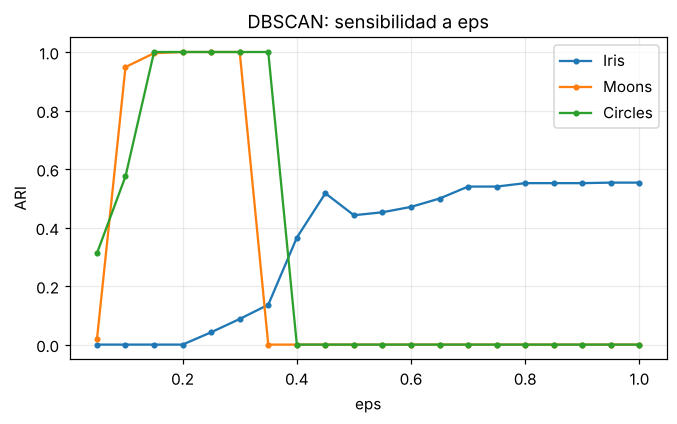

In [13]:
# (a) DBSCAN: ARI en función de eps (min_samples=5) en los tres datasets
datasets = {"Iris": (X_iris, y_iris), "Moons": (X_moons, y_moons), "Circles": (X_circ, y_circ)}
eps_grid = np.round(np.arange(0.05, 1.01, 0.05), 2)
plt.figure(figsize=(7, 3.8))
for nombre, (X, y) in datasets.items():
    plt.plot(eps_grid, [adjusted_rand_score(y, DBSCAN(eps=e, min_samples=5).fit_predict(X)) for e in eps_grid], "o-", ms=3, label=nombre)
plt.xlabel("eps"); plt.ylabel("ARI"); plt.title("DBSCAN: sensibilidad a eps"); plt.legend()
plt.savefig("figuras/sens_dbscan_eps.png", bbox_inches="tight"); plt.show()

In [14]:
# (b) Spectral: affinity='rbf' depende de gamma; 'nearest_neighbors' depende de n_neighbors (ARI en Moons y Circles)
gammas = [0.1, 1, 5, 10, 20, 50]
vecinos = [3, 5, 10, 20, 50]
filas = []
for nombre, (X, y) in {"Moons": (X_moons, y_moons), "Circles": (X_circ, y_circ)}.items():
    for g in gammas:
        lab = SpectralClustering(2, affinity="rbf", gamma=g, random_state=SEED).fit_predict(X)
        filas.append({"dataset": nombre, "affinity": "rbf", "parámetro": f"gamma={g}", "ARI": adjusted_rand_score(y, lab)})
    for nn in vecinos:
        lab = SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=nn, random_state=SEED).fit_predict(X)
        filas.append({"dataset": nombre, "affinity": "nearest_neighbors", "parámetro": f"n_neighbors={nn}", "ARI": adjusted_rand_score(y, lab)})
sens_spec = pd.DataFrame(filas).pivot_table(index=["affinity", "parámetro"], columns="dataset", values="ARI", sort=False).round(3)
sens_spec

dataset                           Moons  Circles
affinity          parámetro                     
rbf               gamma=0.1       0.237   -0.001
                  gamma=1         0.277   -0.002
                  gamma=5         0.467   -0.002
                  gamma=10        0.952    0.203
                  gamma=20        1.000    1.000
                  gamma=50        1.000    1.000
nearest_neighbors n_neighbors=3   0.000    0.000
                  n_neighbors=5   0.067    0.409
                  n_neighbors=10  1.000    1.000
                  n_neighbors=20  1.000    1.000
                  n_neighbors=50  0.992   -0.002

In [15]:
# (c) K-means: sensibilidad a la inicialización (1 sola inicialización aleatoria, 10 semillas distintas) en Iris
aris = [adjusted_rand_score(y_iris, KMeans(3, init="random", n_init=1, random_state=s).fit_predict(X_iris)) for s in range(10)]
print("ARI de K-means con init aleatorio (n_init=1) y 10 semillas:", np.round(aris, 3))
print(f"mín = {min(aris):.3f} | máx = {max(aris):.3f}")

ARI de K-means con init aleatorio (n_init=1) y 10 semillas: [0.645 0.645 0.641 0.645 0.645 0.433 0.62  0.641 0.592 0.592]
mín = 0.433 | máx = 0.645


### 4.1 Conclusiones de la sección 4

- **K-means es el modelo lineal** (fronteras rectas, clústeres convexos): funcionó en Iris (grupos casi esféricos) y falló en Moons y Circles (ARI 0.26 y ≈ 0).
- **DBSCAN y SpectralClustering son no lineales:** resolvieron perfectamente Moons y Circles (ARI = 1.0) porque su criterio es la **conectividad/densidad local**, no la distancia a un centro.
- **Hiperparámetros críticos observados:**
  - *DBSCAN:* `eps` es decisivo (demasiado pequeño → ruido y fragmentación; demasiado grande, p. ej. ≥ 0.4 en Moons/Circles → fusiona todo en un solo clúster). Se ayuda del gráfico de k-distancias. En Iris, ningún `eps` recuperó las 3 especies.
  - *Spectral:* `affinity` y su parámetro asociado. Con `rbf`, `gamma` pequeño (≤ 5) falla en ambos datasets sintéticos; `nearest_neighbors` con `n_neighbors` ≈ 10–20 funciona, pero demasiados vecinos (50) conecta estructuras distintas en Circles.
  - *K-means:* `n_clusters`, `n_init` (con inicialización aleatoria única, el ARI en Iris varió entre ≈ 0.43 y 0.65 según la semilla) y el escalado.
- **Costos y limitaciones:** Spectral necesita construir una matriz de afinidad (costoso en datasets grandes); DBSCAN tiene dificultades con densidades heterogéneas; K-means es el más rápido pero el más restrictivo.

## 5. Resumen consolidado

In [16]:
resumen = pd.concat({"Iris": tabla_iris, "Moons": tabla_moons, "Circles": tabla_circ}, names=["Dataset", "Modelo"])
resumen.to_csv("resultados/resumen_metricas.csv")
resumen[["n_clusters", "% ruido", "ARI", "V-measure", "Silhouette", "Davies-Bouldin"]]

n_clusters  % ruido    ARI  V-measure  Silhouette  \
Dataset Modelo                                                        
Iris    K-means          3.0      0.0  0.620      0.659       0.460   
        DBSCAN           2.0     17.3  0.471      0.541       0.642   
        Spectral         3.0      0.0  0.646      0.684       0.459   
Moons   K-means          2.0      0.0  0.261      0.198       0.487   
        DBSCAN           2.0      0.0  1.000      1.000       0.332   
        Spectral         2.0      0.0  1.000      1.000       0.332   
Circles K-means          2.0      0.0 -0.002      0.000       0.330   
        DBSCAN           2.0      0.0  1.000      1.000       0.157   
        Spectral         2.0      0.0  1.000      1.000       0.157   

                  Davies-Bouldin  
Dataset Modelo                    
Iris    K-means            0.834  
        DBSCAN             0.512  
        Spectral           0.822  
Moons   K-means            0.785  
        DBSCAN             1.153  
        Spectral           1.153  
Circles K-means            1.221  
        DBSCAN           205.776  
        Spectral         205.776

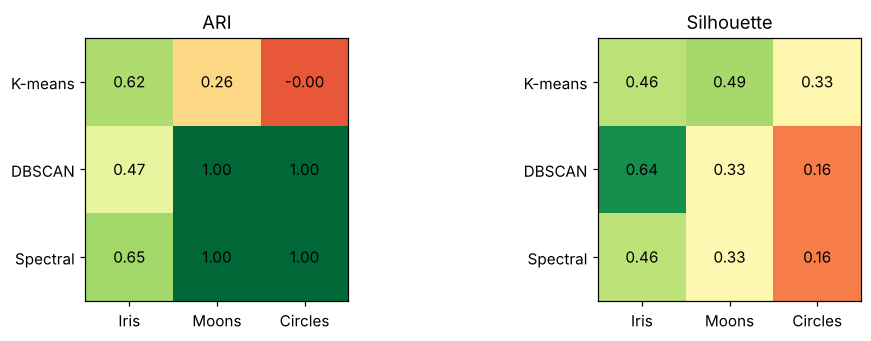

In [17]:
# Heatmap rápido de ARI y Silhouette por modelo y dataset
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, met in zip(axs, ["ARI", "Silhouette"]):
    piv = resumen[met].unstack("Dataset")[["Iris", "Moons", "Circles"]]
    im = ax.imshow(piv.values.astype(float), cmap="RdYlGn", vmin=-0.2 if met=="ARI" else 0, vmax=1 if met=="ARI" else 0.7)
    ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns); ax.set_yticks(range(3)); ax.set_yticklabels(piv.index)
    for i in range(3):
        for j in range(3): ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
    ax.set_title(met); ax.grid(False)
fig.tight_layout(); fig.savefig("figuras/resumen_heatmap.png", bbox_inches="tight"); plt.show()

## 6. Conclusión general

1. **No existe un algoritmo "mejor" universal:** la elección depende de la forma de los clústeres. K-means es suficiente para grupos compactos (Iris); para formas curvas o anidadas (Moons, Circles) se necesitan métodos basados en densidad o en grafos (DBSCAN, Spectral).
2. **Las métricas internas pueden engañar:** en Moons y Circles el modelo equivocado (K-means) obtiene los mejores Silhouette/DBI/CH, y en Iris el DBSCAN con peor ARI obtiene las mejores internas. Se debe combinar métricas externas (si hay etiquetas), internas, **y la inspección visual**.
3. **Los hiperparámetros críticos** (`eps`, `gamma`/`n_neighbors`, `k`, `n_init`) pueden cambiar el resultado de ARI ≈ 0 a ARI = 1; deben justificarse con herramientas como el gráfico de k-distancias, el codo y barridos de sensibilidad.
